# Gravity Spy glitch classification — ITRI626 project notebook

**Group:** Student 1 — [name] (shared pipeline, custom CNN) · Student 2 — [name] (EfficientNetV2-S) · Student 3 — [name] (Swin-Tiny)

This notebook documents the dataset, the experimental setup and the results of comparing three image-classification models on LIGO Gravity Spy glitch spectrograms. The training code lives in the repository (`train.py`, `evaluate.py`, `models/`, `data/`); this notebook calls that same code, so there is one implementation, not two.

**How to run:** *Kernel → Restart & Run All.* With `RETRAIN = False` (the default) it loads the trained results from `outputs/` and takes about two minutes. Set `RETRAIN = True` to retrain all three models first (about 25 minutes on an RTX 5070).

| Spec requirement | Section |
|---|---|
| §5 Dataset source, licence, classes, labels, cleaning, imbalance, examples | 1 – 5 |
| §7.1 Split, seed, per-split counts and class distribution, leakage prevention | 3 |
| §7.2 Preprocessing and augmentation | 6 |
| §7.3 Models, hyperparameters, software and hardware | 7 – 8 |
| §8 Metrics, curves, confusion matrices, examples, comparison, error analysis | 9 – 11 |

In [1]:
import os, sys, io, json, hashlib, itertools, random
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import h5py
import timm
from PIL import Image as PILImage
from IPython.display import display, Markdown, Image

from config import CLASSES, CLASS_TO_IDX, SPLITS, H5_NAME, METADATA_NAME, Config
from data.dataset import build_index, split_records, assert_no_id_leakage, counts_by_split, GravitySpyDataset
from data.transforms import build_transforms, Compose, Resize
from models import registry
from utils.env_info import collect_env_info
from utils.metrics import compute_class_weights, compute_metrics
import utils.plotting      # selects matplotlib's non-interactive Agg backend on import...
%matplotlib inline
import matplotlib.pyplot as plt   # ...so switch back to inline plots for this notebook

pd.set_option("display.precision", 4)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)

RETRAIN = False                       # True = retrain all three models first (~25 min)
cfg = Config()
OUT = ROOT / "outputs"
H5_PATH = ROOT / "dataset" / H5_NAME
MODELS = ["custom_cnn", "transfer_cnn", "transformer"]
LABELS = {"custom_cnn": "Custom CNN (Student 1)",
          "transfer_cnn": "EfficientNetV2-S (Student 2)",
          "transformer": "Swin-Tiny (Student 3)"}


def show_png(path, max_width=1100):
    """Display a saved figure, downscaled so the notebook file stays small."""
    im = PILImage.open(path).convert("RGB")
    if im.width > max_width:
        im = im.resize((max_width, round(im.height * max_width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=88)
    display(Image(data=buf.getvalue(), format="jpeg"))


def spectrogram(ax, img, title=""):
    """Draw one spectrogram the right way up.

    The stored arrays are image-style: row 0 is the top of the plot, i.e. the
    highest frequency. origin="upper" keeps frequency increasing upward.
    """
    ax.imshow(img, cmap="viridis", aspect="auto", origin="upper")
    ax.set_title(title, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])


print("repo root :", ROOT)
print("dataset   :", H5_PATH, "(found)" if H5_PATH.exists() else "(MISSING - see README 'Getting the data')")
print("RETRAIN   :", RETRAIN)

repo root : C:\Users\kylek\Desktop\2026 Honours\AI\Sem2\Project\gh-repo
dataset   : C:\Users\kylek\Desktop\2026 Honours\AI\Sem2\Project\gh-repo\dataset\trainingsetv1d1.h5 (found)
RETRAIN   : False


### Software and hardware

Spec §7.3 asks for the framework, library versions and the GPU with its memory. This is the environment the notebook is running in; each trained model also stores the environment it was trained in, in `outputs/<model>/env.json` (shown in section 8).

In [2]:
env = collect_env_info()
env["cpu cores"] = os.cpu_count()
pd.Series(env, name="value").to_frame()

,value
timestamp,2026-10-23T11:40:03
python,3.12.0
platform,Windows-11-10.0.26200-SP0
torch,2.11.0+cu128
numpy,2.5.2
sklearn,1.9.0
timm,1.0.29
cuda,12.8
gpu,NVIDIA GeForce RTX 5070
gpu_memory_gb,11.91


## 1. Dataset: source, access and licence

| | |
|---|---|
| **Dataset** | Gravity Spy training set, version 1.1 ("Updated Gravity Spy Data Set") |
| **Access** | Zenodo, DOI [10.5281/zenodo.1476551](https://doi.org/10.5281/zenodo.1476551) |
| **Licence** | Creative Commons Attribution 4.0 (CC BY 4.0) — free to use, adapt and redistribute with attribution |
| **File used** | `trainingsetv1d1.h5` (3.1 GB), plus `trainingset_v1d1_metadata.csv` |
| **Not used** | `trainingsetv1d1.tar.gz` — the same glitches as raw PNG renders |
| **Size** | 7,966 labelled glitches, 22 classes |
| **Citation** | Bahaadini et al. (2018), *Information Sciences* 444; Zevin et al. (2017), *Classical and Quantum Gravity* 34(6) |

Papers often quote 8,583 glitches; that figure belongs to the original release (Zenodo record 1476156). This updated release contains 7,966.

Each glitch is a time–frequency **spectrogram** (an Omega/Q-transform of the detector strain): time runs left to right, frequency increases upward on a log scale, and brightness is normalised energy. Every glitch is rendered at four time windows — 0.5, 1.0, 2.0 and 4.0 seconds. **We use the 2.0 s view.** The HDF5 file stores each view as a `1 × 140 × 170` array that is already cropped (no axes or labels) and scaled to [0, 1].

Below we confirm the file is intact by comparing its MD5 checksum with the value published on the Zenodo record.

In [3]:
size = H5_PATH.stat().st_size
digest = hashlib.md5()
with open(H5_PATH, "rb") as fh:
    for chunk in iter(lambda: fh.read(1 << 22), b""):
        digest.update(chunk)
EXPECTED_MD5 = "a6665b4ebee7b4ea57164ee743c2bd11"   # published on the Zenodo record
print("file     :", H5_PATH.name)
print("size     : {:,} bytes ({:.2f} GB)".format(size, size / 1e9))
print("MD5      :", digest.hexdigest())
print("expected :", EXPECTED_MD5)
print("intact   :", digest.hexdigest() == EXPECTED_MD5)

file     : trainingsetv1d1.h5
size     : 3,051,325,064 bytes (3.05 GB)
MD5      : a6665b4ebee7b4ea57164ee743c2bd11
expected : a6665b4ebee7b4ea57164ee743c2bd11
intact   : True


## 2. Class definitions and labels

The 22 classes are the glitch morphologies defined by the Gravity Spy project. We used them unchanged: they are an established, physically motivated taxonomy, and keeping them makes our results comparable with published work. The descriptions below are paraphrased from Zevin et al. (2017).

| Class | What it looks like / where it comes from |
|---|---|
| 1080Lines | Narrow, intermittent features near 1080 Hz |
| 1400Ripples | Short ripple-like features near 1400 Hz |
| Air_Compressor | Short low-frequency feature near 50 Hz, linked to air compressors at the site |
| Blip | Very short (milliseconds), broadband, symmetric teardrop shape; cause largely unknown |
| Chirp | Frequency rising over time, the shape expected from a compact-binary signal |
| Extremely_Loud | Very high-amplitude transient that saturates much of the plot |
| Helix | Repeating short vertical features with a helical appearance |
| Koi_Fish | Like a large Blip: a bright low-frequency "body" with a tail extending upward |
| Light_Modulation | Periodic broadband features from modulation of the laser light |
| Low_Frequency_Burst | Hump of excess power at low frequency |
| Low_Frequency_Lines | Horizontal lines at low frequency |
| No_Glitch | Background noise only; no visible glitch |
| None_of_the_Above | A clear glitch that fits none of the other classes |
| Paired_Doves | Pairs of short curved, chirp-like features close together in time |
| Power_Line | Line at the 60 Hz mains frequency (US power grid) and its harmonics |
| Repeating_Blips | Several Blips at regular intervals |
| Scattered_Light | Low-frequency arches caused by light scattering off moving surfaces |
| Scratchy | Long-duration, wispy noise at mid frequencies |
| Tomte | Short low-frequency transient with a triangular shape |
| Violin_Mode | Narrow lines near 500 Hz from resonance of the mirror suspension fibres |
| Wandering_Line | Narrow line whose frequency drifts over time |
| Whistle | Narrow curved features at high frequency (arch-, V- or W-shaped), typically from radio-frequency beat notes |

**How the labels were obtained.** The labels come from the Gravity Spy project, which combines classifications by volunteers on the Zooniverse citizen-science platform with review by LIGO detector-characterisation experts (Zevin et al., 2017; Bahaadini et al., 2018).

**How we checked them.** We did not relabel any glitch. We checked that (1) the label and split implied by each glitch's location in the HDF5 file agree with the separately published metadata CSV, for every glitch (section 3); and (2) no two genuinely identical images carry different labels (section 4). The labels we cannot verify are those on the blank images described in section 4: an image with no content cannot be checked against its label.

## 3. Training, validation and test split

**We use the dataset's own split, assigned per glitch, and never split images at random.**

The dataset ships a canonical `train` / `validation` / `test` assignment (`sample_type`). It is roughly 70 / 15 / 15, which matches the split the spec suggests.

**Leakage prevention.** Each glitch is stored as four images — its four duration views. These are four pictures of the *same physical event*, so they form a group in exactly the sense of spec §7.1. Splitting images at random would put views of one glitch on both sides of the train/test boundary, and the test score would partly measure memorisation. The canonical split is assigned per glitch, and all four views are stored together inside one `<label>/<split>/<gravityspy_id>/` group in the HDF5 file, so they cannot be separated. We also only use one view (2.0 s) per glitch. The cell below checks this rather than assuming it, and confirms the labels against the metadata CSV.

The **same test set** is used for all three models. The random seed (42) controls weight initialisation, data-loader shuffling and augmentation; the split itself involves no randomness.

In [4]:
records, _ = build_index(cfg)
grouped = split_records(records)
assert_no_id_leakage(grouped)   # raises an error if any glitch id appears in two splits

# All four duration views of every glitch must live together in one group.
complete = 0
with h5py.File(H5_PATH, "r") as f:
    for r in records:
        if set(f[r.label][r.split][r.gravityspy_id].keys()) == {"0.5.png", "1.0.png", "2.0.png", "4.0.png"}:
            complete += 1

# Independent check of every label and split against the published metadata CSV.
meta = pd.read_csv(ROOT / "dataset" / METADATA_NAME).set_index("gravityspy_id")
agree = sum(meta.at[r.gravityspy_id, "label"] == r.label and
            meta.at[r.gravityspy_id, "sample_type"] == r.split for r in records)

print("glitches indexed (2.0 s view)            : %d" % len(records))
print("unique glitch ids                        : %d" % len({r.gravityspy_id for r in records}))
print("glitches with all 4 views in one group   : %d" % complete)
print("label and split agree with metadata CSV  : %d / %d" % (agree, len(records)))
print("glitch ids found in more than one split  : 0   (leakage check passed)")
print("random seed                              : %d" % cfg.seed)
print()
for s in SPLITS:
    print("  %-10s %5d glitches  (%.1f%%)" % (s, len(grouped[s]), 100 * len(grouped[s]) / len(records)))

glitches indexed (2.0 s view)            : 7966
unique glitch ids                        : 7966
glitches with all 4 views in one group   : 7966
label and split agree with metadata CSV  : 7966 / 7966
glitch ids found in more than one split  : 0   (leakage check passed)
random seed                              : 42

  train       5587 glitches  (70.1%)
  validation  1200 glitches  (15.1%)
  test        1179 glitches  (14.8%)


### Class distribution in each split

Counts per class and split, the share of each split, and the loss weight each class receives (section 6). The canonical split keeps every class at roughly 70 / 15 / 15, so all three splits have the same class balance.

In [5]:
counts = counts_by_split(records)
table = pd.DataFrame({s: counts[s] for s in SPLITS})[list(SPLITS)]
table["total"] = table.sum(axis=1)
table["loss weight"] = compute_class_weights(table["train"].tolist())   # 1/sqrt(n), mean 1
for s in SPLITS:
    table["%s %%" % s] = 100 * table[s] / table["total"]
table = table.sort_values("total", ascending=False)

ratio = table["train"].max() / table["train"].min()
print("largest / smallest training class : %d / %d = %.1f : 1"
      % (table["train"].max(), table["train"].min(), ratio))
print("loss-weight ratio (1/sqrt(n))     : %.2f / %.2f = %.1f : 1"
      % (table["loss weight"].max(), table["loss weight"].min(),
         table["loss weight"].max() / table["loss weight"].min()))
display(table.round({"loss weight": 2, "train %": 1, "validation %": 1, "test %": 1}))
print("totals:", {s: int(table[s].sum()) for s in list(SPLITS) + ["total"]})

largest / smallest training class : 1274 / 19 = 67.1 : 1
loss-weight ratio (1/sqrt(n))     : 2.51 / 0.31 = 8.2 : 1


,train,validation,test,total,loss weight,train %,validation %,test %
Blip,1274,275,272,1821,0.31,70.0,15.1,14.9
Koi_Fish,498,106,102,706,0.49,70.5,15.0,14.4
Low_Frequency_Burst,437,94,90,621,0.52,70.4,15.1,14.5
Light_Modulation,361,73,78,512,0.58,70.5,14.3,15.2
Power_Line,314,67,68,449,0.62,69.9,14.9,15.1
Extremely_Loud,316,67,64,447,0.62,70.7,15.0,14.3
Low_Frequency_Lines,315,66,66,447,0.62,70.5,14.8,14.8
Scattered_Light,308,68,67,443,0.62,69.5,15.3,15.1
Violin_Mode,284,64,64,412,0.65,68.9,15.5,15.5
Scratchy,237,50,50,337,0.71,70.3,14.8,14.8


totals: {'train': 5587, 'validation': 1200, 'test': 1179, 'total': 7966}


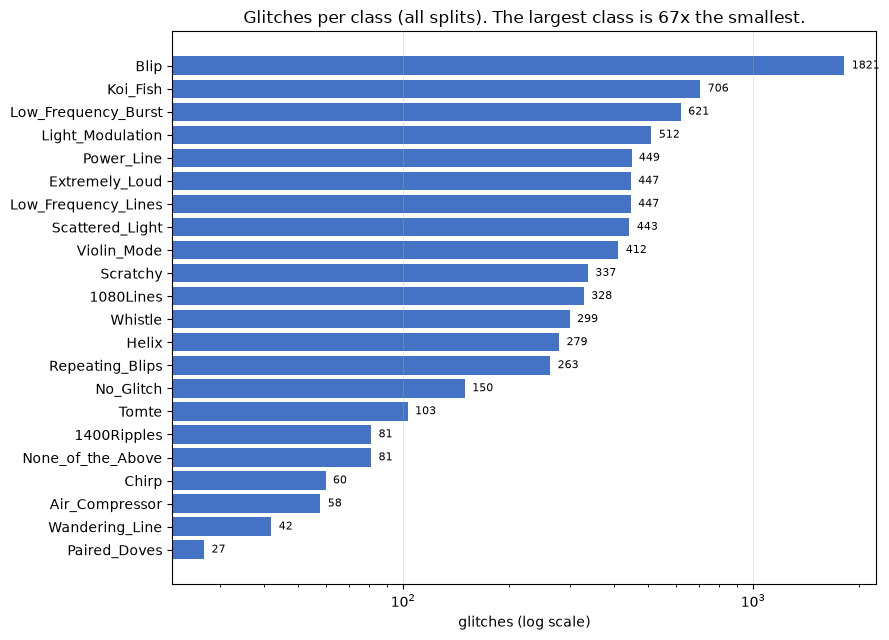

In [6]:
fig, ax = plt.subplots(figsize=(9, 6.5))
order = table.index[::-1]
ax.barh(order, table.loc[order, "total"], color="#4472c4")
for i, c in enumerate(order):
    ax.text(table.loc[c, "total"] * 1.05, i, "%d" % table.loc[c, "total"], va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("glitches (log scale)")
ax.set_title("Glitches per class (all splits). The largest class is %.0fx the smallest." % ratio)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Split files.** Spec §11 asks for the split files or a script that recreates them. The cell below writes the exact split to `splits/`; `data/dataset.py` also recreates it from the HDF5 file.

In [7]:
split_dir = ROOT / "splits"
split_dir.mkdir(exist_ok=True)
for s in SPLITS:
    pd.DataFrame([{"gravityspy_id": r.gravityspy_id, "label": r.label, "sample_type": r.split}
                  for r in grouped[s]]).to_csv(split_dir / ("%s.csv" % s), index=False)
print("written:", ", ".join(sorted(p.name for p in split_dir.glob("*.csv"))))

written: blank_images.csv, test.csv, train.csv, validation.csv


## 4. Data quality and cleaning

Spec §5 asks for corrupted files, duplicates, irrelevant samples and uncertain labels. We read every image and checked:

- **corrupted or malformed arrays** — wrong shape, NaNs, values outside [0, 1];
- **blank images** — every pixel identical, so the image carries no information;
- **exact duplicates** — byte-identical arrays;
- **near-duplicates** — a coarse 14 × 17 average hash flags candidates, which are then compared pixel by pixel.

In [8]:
rows = []
with h5py.File(H5_PATH, "r") as f:
    for r in records:
        raw = np.asarray(f[r.locator], dtype=np.float32)
        a = raw[0]
        small = a.reshape(14, 10, 17, 10).mean(axis=(1, 3))
        rows.append({"gravityspy_id": r.gravityspy_id, "label": r.label, "split": r.split,
                     "shape_ok": raw.shape == (1, 140, 170), "has_nan": bool(np.isnan(a).any()),
                     "min": float(a.min()), "max": float(a.max()), "std": float(a.std()),
                     "floor_frac": float((a == a.min()).mean()),
                     "md5": hashlib.md5(a.tobytes()).hexdigest(),
                     "ahash": (small > small.mean()).tobytes().hex()})
q = pd.DataFrame(rows)
q["blank"] = q["std"] < 1e-6

print("images read                  : %d" % len(q))
print("wrong shape / NaN values     : %d / %d" % ((~q.shape_ok).sum(), q.has_nan.sum()))
print("value range                  : %.4f to %.4f" % (q["min"].min(), q["max"].max()))
print("blank (all pixels identical) : %d  (%.2f%%)" % (q.blank.sum(), 100 * q.blank.mean()))
print("their constant value         :", q.loc[q.blank, "min"].round(6).unique())

images read                  : 7966
wrong shape / NaN values     : 0 / 0
value range                  : 0.0832 to 0.8694
blank (all pixels identical) : 134  (1.68%)
their constant value         : [0.083223]


### Blank images

A blank image is a defect in the published dataset: the array really is constant on disk, so it is not a loading error. Below: which classes they belong to, whether other duration views of the same glitch are also blank, and how the count changes with a looser definition of "blank".

In [9]:
by_class = (q.groupby("label")["blank"].agg(blank="sum", total="size")
              .query("blank > 0").sort_values("blank", ascending=False))
by_class["% of class"] = (100 * by_class["blank"] / by_class["total"]).round(1)
display(by_class)
print("blank images per split:", q[q.blank].groupby("split").size().to_dict())

with h5py.File(H5_PATH, "r") as f:
    all_four = sum(
        all(float(np.asarray(f["%s/%s/%s/%s.png" % (l, s, g, d)]).std()) < 1e-6
            for d in ("0.5", "1.0", "2.0", "4.0"))
        for l, s, g in q.loc[q.blank, ["label", "split", "gravityspy_id"]].itertuples(index=False))
print("blank at all four durations  : %d of %d  (so changing the duration does not recover them)"
      % (all_four, q.blank.sum()))

sens = pd.DataFrame([{"definition of blank": name, "images": int(mask.sum()),
                      "Extremely_Loud": int((mask & (q.label == "Extremely_Loud")).sum()),
                      "Paired_Doves": int((mask & (q.label == "Paired_Doves")).sum())}
                     for name, mask in [("every pixel identical (used)", q.blank),
                                        (">= 99.9% of pixels at minimum", q.floor_frac >= 0.999),
                                        (">= 99% of pixels at minimum", q.floor_frac >= 0.99),
                                        (">= 95% of pixels at minimum", q.floor_frac >= 0.95)]])
display(sens.set_index("definition of blank"))

q.loc[q.blank, ["gravityspy_id", "label", "split"]].to_csv(ROOT / "splits" / "blank_images.csv", index=False)
print("blank image list written to splits/blank_images.csv")

,blank,total,% of class
label,,,
Extremely_Loud,108,447,24.2
No_Glitch,9,150,6.0
Paired_Doves,8,27,29.6
Blip,2,1821,0.1
Low_Frequency_Burst,2,621,0.3
Koi_Fish,2,706,0.3
None_of_the_Above,2,81,2.5
Whistle,1,299,0.3


blank images per split: {'test': 19, 'train': 97, 'validation': 18}
blank at all four durations  : 107 of 134  (so changing the duration does not recover them)


,images,Extremely_Loud,Paired_Doves
definition of blank,,,
every pixel identical (used),134,108,8
>= 99.9% of pixels at minimum,138,112,8
>= 99% of pixels at minimum,147,121,8
>= 95% of pixels at minimum,156,129,8


blank image list written to splits/blank_images.csv


### Duplicates

All blank images are identical to one another (the same constant value), so they are excluded here and treated above. Among the remaining images we look for exact and near-duplicates. For context, the last line shows how strongly two *unrelated* `Extremely_Loud` images correlate: saturated images look alike, so a high correlation alone does not mean a duplicate.

In [10]:
real = q[~q.blank]
exact = real.groupby("md5").filter(lambda g: len(g) > 1)
print("exact duplicates among the %d non-blank images: %d" % (len(real), len(exact)))

cand = real.groupby("ahash").filter(lambda g: len(g) > 1)
pairs = []
with h5py.File(H5_PATH, "r") as f:
    load = lambda r: np.asarray(f["%s/%s/%s/2.0.png" % (r.label, r.split, r.gravityspy_id)], dtype=np.float32)[0]
    for _, g in cand.groupby("ahash"):
        for (_, a), (_, b) in itertools.combinations(g.iterrows(), 2):
            x, y = load(a), load(b)
            pairs.append({"image A": "%s / %s / %s" % (a.label, a.split, a.gravityspy_id),
                          "image B": "%s / %s / %s" % (b.label, b.split, b.gravityspy_id),
                          "pixel correlation": float(np.corrcoef(x.ravel(), y.ravel())[0, 1]),
                          "A % empty": round(100 * a.floor_frac, 1),
                          "B % empty": round(100 * b.floor_frac, 1)})
    print("near-duplicate candidates from the average hash: %d pair(s)" % len(pairs))
    display(pd.DataFrame(pairs))

    rng = np.random.default_rng(cfg.seed)
    el = real[real.label == "Extremely_Loud"]
    corrs = [np.corrcoef(load(el.iloc[i]).ravel(), load(el.iloc[j]).ravel())[0, 1]
             for i, j in (rng.choice(len(el), 2, replace=False) for _ in range(300))]
print("unrelated Extremely_Loud pairs: median correlation %.2f, 99th percentile %.2f"
      % (np.median(corrs), np.percentile(corrs, 99)))

exact duplicates among the 7832 non-blank images: 0


near-duplicate candidates from the average hash: 4 pair(s)


,image A,image B,pixel correlation,A % empty,B % empty
0,Extremely_Loud / train / TEbrworflu,Extremely_Loud / train / vYwk4jNoCQ,-0.0004,100.0,99.9
1,Extremely_Loud / train / Pt8sXmX8bR,Extremely_Loud / validation / RhU54mR0Ze,0.9899,99.9,99.8
2,Extremely_Loud / test / x74ltV5sTB,Extremely_Loud / train / Ufig43OHej,0.9046,22.3,29.7
3,No_Glitch / train / 8r54exnm6L,Power_Line / train / IfIo5hADT1,0.4179,65.7,73.6


unrelated Extremely_Loud pairs: median correlation 0.38, 99th percentile 0.93


**Interpretation.** There are no genuine duplicates. Every near-identical pair consists of images that are 99.8–100% empty, which match each other the way any two blank pages do. The remaining candidates correlate no more than unrelated images of the same class, or carry different labels and are visibly different glitches.

### Cleaning decision, and class counts before and after

Nothing was removed for the reported results. The 134 blank images are **kept**:

- removing them would make our test set different from the canonical Gravity Spy test set, so results would no longer be comparable with published work;
- all three models must be tested on the same images, and keeping the published set makes that automatic.

Their effect is measured instead (section 11): we report every model with and without them. The pipeline can exclude them with `python train.py --drop-blank-images`, and `compare.py` refuses to compare models that disagree on this setting.

In [11]:
ba = pd.DataFrame({"as distributed": q.groupby("label").size(),
                   "blank": q.groupby("label")["blank"].sum()}).reindex(CLASSES)
ba["if blanks excluded"] = ba["as distributed"] - ba["blank"]
ba.loc["TOTAL"] = ba.sum()
ba.astype(int)

,as distributed,blank,if blanks excluded
label,,,
1080Lines,328,0,328
1400Ripples,81,0,81
Air_Compressor,58,0,58
Blip,1821,2,1819
Chirp,60,0,60
Extremely_Loud,447,108,339
Helix,279,0,279
Koi_Fish,706,2,704
Light_Modulation,512,0,512


## 5. Representative examples from every class

One training image per class (2.0 s view). Time runs left to right across the 2-second window; frequency increases upward. The final panel shows one of the blank images.

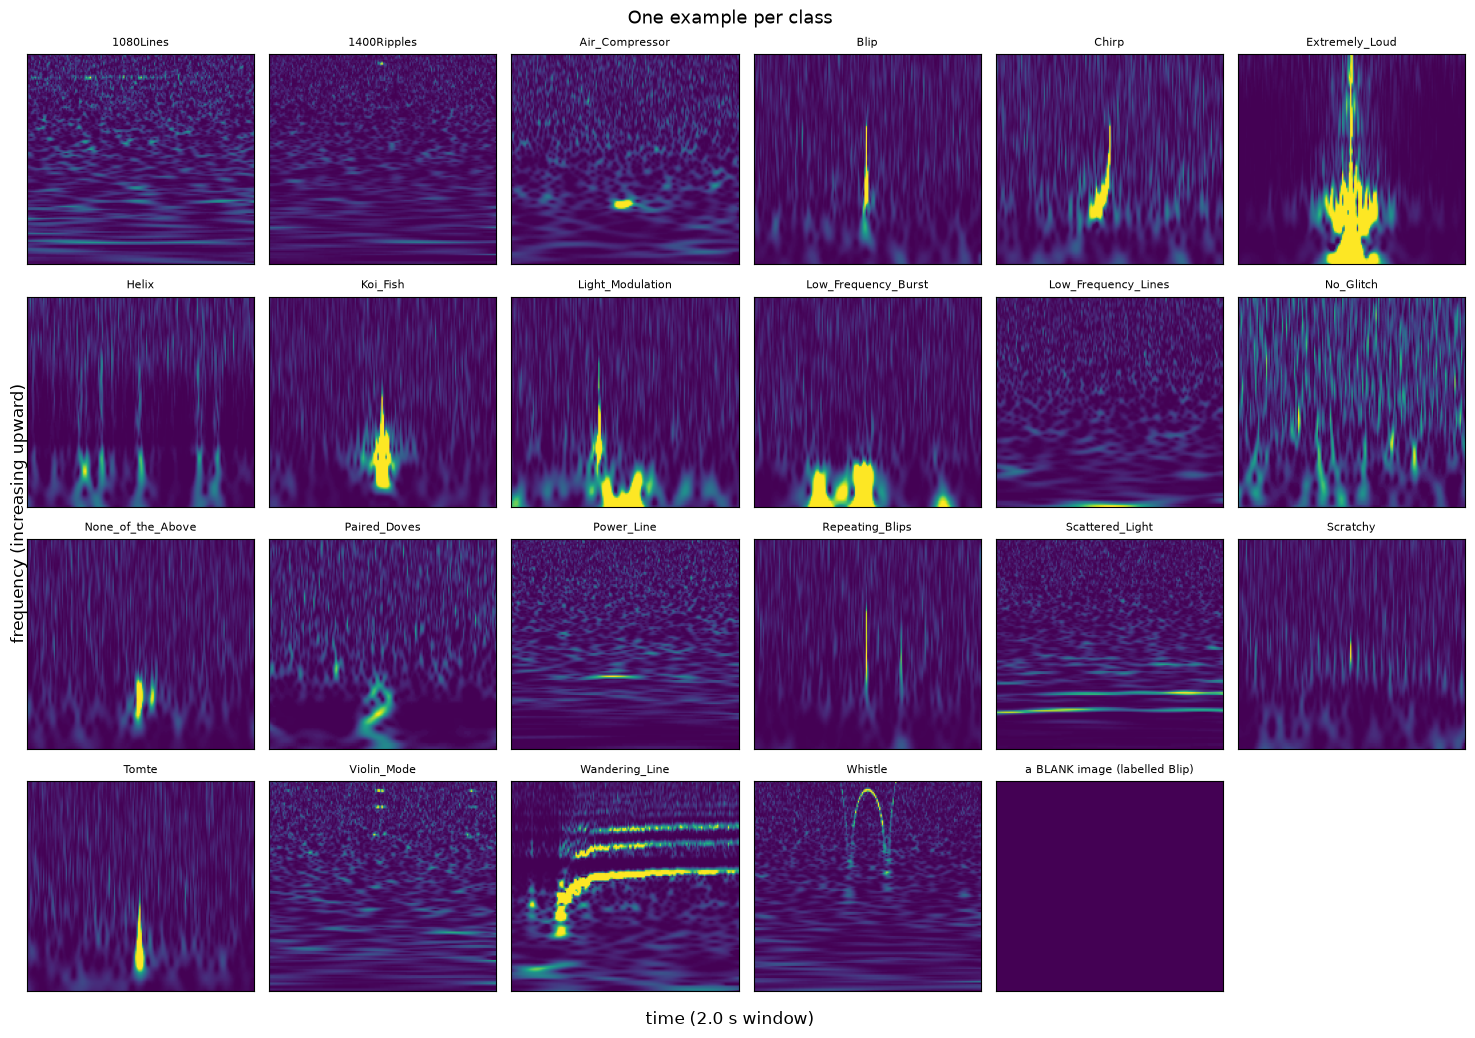

In [12]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))
with h5py.File(H5_PATH, "r") as f:
    for ax, cls in zip(axes.flat, CLASSES):
        r = q[(q.label == cls) & (q.split == "train") & (~q.blank)].iloc[0]
        spectrogram(ax, np.asarray(f["%s/train/%s/2.0.png" % (cls, r.gravityspy_id)])[0], cls)
    b = q[q.blank].iloc[0]
    spectrogram(axes.flat[22], np.asarray(f["%s/%s/%s/2.0.png" % (b.label, b.split, b.gravityspy_id)])[0],
                "a BLANK image (labelled %s)" % b.label)
axes.flat[23].axis("off")
fig.supxlabel("time (2.0 s window)")
fig.supylabel("frequency (increasing upward)")
fig.suptitle("One example per class", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Preprocessing and augmentation

**Preprocessing (all splits, all models):**

1. Read the `1 × 140 × 170` array from HDF5 — already cropped and scaled to [0, 1], so no cropping or axis removal is needed.
2. Copy the single grey channel to three identical channels, so ImageNet-pretrained models accept the input without changing their first layer.
3. Resize to the model's input size with antialiasing: 140 × 170 (native) for the custom CNN, 224 × 224 for EfficientNetV2-S and Swin-Tiny.
4. Normalise each channel with the ImageNet mean and standard deviation.

**Augmentation (training split only).** A spectrogram is not a photograph: the horizontal axis is time and the vertical axis is frequency, and several classes are *defined* by frequency (Violin_Mode near 500 Hz, Power_Line at 60 Hz, 1080Lines near 1080 Hz). The usual photo augmentations would therefore create physically impossible glitches.

| Augmentation | Used | Why |
|---|---|---|
| Small time shift (±8% of width) | yes | Glitches are not always centred in the window |
| SpecAugment time and frequency masking (Park et al., 2019) | yes | Forces classification from partial evidence instead of one narrow band |
| Brightness / contrast ±15% | yes | Glitch loudness varies and is not class-defining |
| Vertical flip | **no** | Swaps low and high frequencies — turns one class into a different or impossible one |
| Rotation, shear, random crop | **no** | Mixes the time and frequency axes |
| Horizontal flip | **off** | Time reversal: a reversed Chirp sweeps downward, which no chirp does |

Validation and test images are only resized and normalised.

In [13]:
for m in MODELS:
    size = registry.get_input_size(m)
    tr = build_transforms(cfg, size, train=True)
    ev = build_transforms(cfg, size, train=False)
    print("%-13s input %dx%d" % (m, size[0], size[1]))
    print("   train     : " + " -> ".join(type(t).__name__ for t in tr.transforms))
    print("   val / test: " + " -> ".join(type(t).__name__ for t in ev.transforms))

custom_cnn    input 140x170
   train     : Resize -> RandomTimeShift -> SpecAugment -> RandomBrightnessContrast -> Normalise
   val / test: Resize -> Normalise
transfer_cnn  input 224x224
   train     : Resize -> RandomTimeShift -> SpecAugment -> RandomBrightnessContrast -> Normalise
   val / test: Resize -> Normalise
transformer   input 224x224
   train     : Resize -> RandomTimeShift -> SpecAugment -> RandomBrightnessContrast -> Normalise
   val / test: Resize -> Normalise


Why vertical flips are excluded, on a real Chirp: the original sweeps **upward** in frequency over time, as the physics requires. Flipped vertically it sweeps downward — a signal that never occurs, so training on it would teach the model something false. Then eight random training augmentations of the same image.

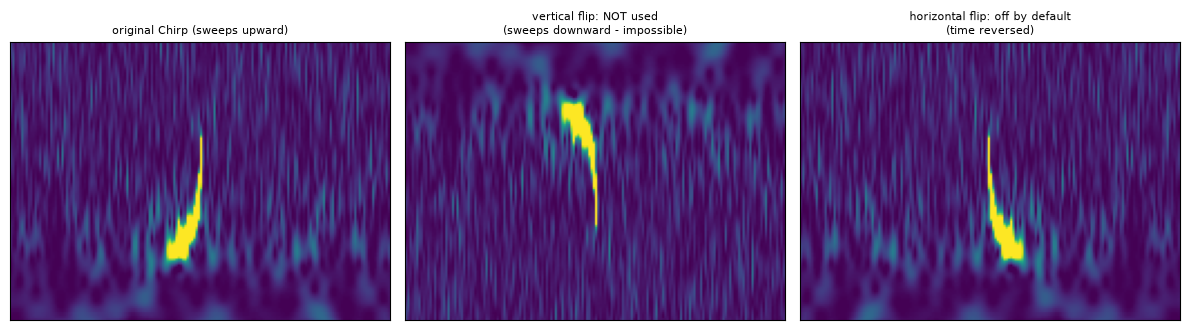

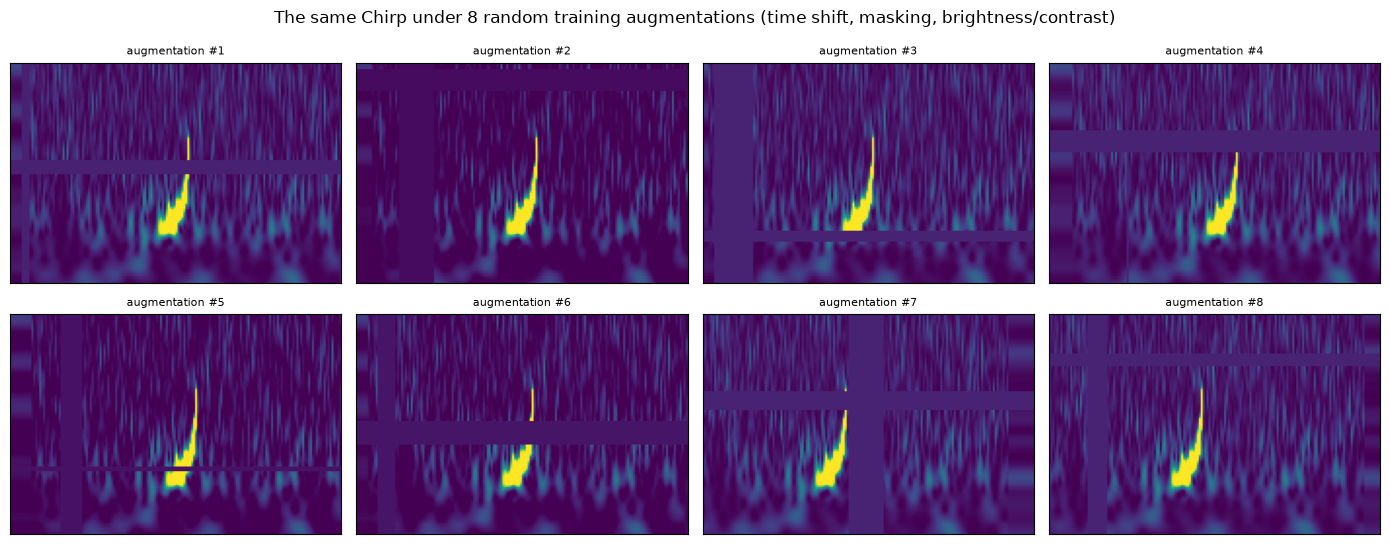

In [14]:
rec = next(r for r in grouped["train"] if r.label == "Chirp")
original = GravitySpyDataset([rec], H5_PATH, Compose([Resize((140, 170))]))[0][0][0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
spectrogram(axes[0], original, "original Chirp (sweeps upward)")
spectrogram(axes[1], original[::-1], "vertical flip: NOT used\n(sweeps downward - impossible)")
spectrogram(axes[2], original[:, ::-1], "horizontal flip: off by default\n(time reversed)")
plt.tight_layout(); plt.show()

aug = build_transforms(cfg, (140, 170), train=True)
aug.transforms = [t for t in aug.transforms if type(t).__name__ != "Normalise"]   # keep [0, 1] for display
ds = GravitySpyDataset([rec], H5_PATH, aug)
random.seed(cfg.seed)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for i, ax in enumerate(axes.flat, 1):
    spectrogram(ax, ds[0][0][0].numpy(), "augmentation #%d" % i)
fig.suptitle("The same Chirp under 8 random training augmentations (time shift, masking, brightness/contrast)")
plt.tight_layout(); plt.show()

## 7. Models

Spec §6 requires three models from three different families, at least one using transfer learning.

| Model | Family | Approach |
|---|---|---|
| Custom CNN (Student 1) | Convolutional network | Trained from scratch — the baseline |
| EfficientNetV2-S (Student 2) | Convolutional network (EfficientNet family) | Transfer learning from ImageNet |
| Swin-Tiny (Student 3) | Vision transformer (Swin family) | Transfer learning from ImageNet |

**Custom CNN.** Five blocks of (3×3 convolution → batch normalisation → ReLU) × 2 → 2×2 max-pooling, with widths 32, 64, 128, 256, 256; then global average pooling, dropout 0.4 and a linear layer to 22 classes. It runs at the spectrograms' native 140 × 170, so no detail is lost or invented by resizing.

**Transfer-learning approach (both pretrained models).** The ImageNet weights are loaded through `timm`, and the 1,000-class ImageNet head is replaced by a new, randomly initialised 22-class head. The whole network is then fine-tuned end to end — no layers are frozen — with a smaller learning rate than the from-scratch baseline (section 8), so the pretrained features are adapted rather than overwritten.

All three models are registered in `models/registry.py` and trained by the same `train.py`, so they share the loader, augmentation, loss, optimiser, schedule and evaluation code.

In [15]:
FAMILY = {"custom_cnn": "CNN, from scratch",
          "transfer_cnn": "CNN (EfficientNet), transfer learning",
          "transformer": "Vision transformer (Swin), transfer learning"}
rows = []
for m in MODELS:
    spec = registry.get_spec(m)
    net = registry.build_model(m, len(CLASSES), pretrained=False)   # architecture only, no download
    pc = getattr(net, "pretrained_cfg", None) or {}
    rows.append({"model": LABELS[m], "family": FAMILY[m],
                 "architecture": pc.get("architecture", "CustomCNN (models/custom_cnn.py)"),
                 "pretrained weights": ("timm/%s.%s" % (pc["architecture"], pc["tag"])
                                        if spec.supports_pretrained else "none (random initialisation)"),
                 "input size": "%d x %d" % spec.input_size,
                 "parameters": "{:,}".format(sum(p.numel() for p in net.parameters()))})
pd.DataFrame(rows).set_index("model")

,family,architecture,pretrained weights,input size,parameters
model,,,,,
Custom CNN (Student 1),"CNN, from scratch",CustomCNN (models/custom_cnn.py),none (random initialisation),140 x 170,"2,359,542"
EfficientNetV2-S (Student 2),"CNN (EfficientNet), transfer learning",tf_efficientnetv2_s,timm/tf_efficientnetv2_s.in21k_ft_in1k,224 x 224,"20,205,670"
Swin-Tiny (Student 3),"Vision transformer (Swin), transfer learning",swin_tiny_patch4_window7_224,timm/swin_tiny_patch4_window7_224.ms_in1k,224 x 224,"27,536,272"


`in21k_ft_in1k` means pretrained on ImageNet-21k then fine-tuned on ImageNet-1k; `ms_in1k` means Microsoft's ImageNet-1k weights.

## 8. Experimental setup

Read directly from each model's saved run configuration (`outputs/<model>/config.json`), training history and training environment (`env.json`).

**Fairness.** Everything that defines the task is identical: split, test set, seed, preprocessing, augmentation, class weighting, loss, optimiser, learning-rate schedule and early-stopping rule. Three settings differ on purpose, as spec §6 allows when an architecture needs it:

- **Learning rate.** The pretrained models use a lower rate (1e-4 and 3e-5) than the from-scratch CNN (3e-4). A large rate would wash out the pretrained features; the transformer is the most sensitive because it has no built-in convolutional assumptions to fall back on.
- **Epochs.** The pretrained models start from good features and converge far sooner, so they get 25 and 20 epochs against 60. Early stopping picks the best epoch for every model.
- **Weight decay** is 0.05 for the transformer, the usual setting for Swin, against 1e-4 for the CNNs.

Every model is checkpointed at its best validation macro-F1, and that checkpoint is the one evaluated on the test set.

In [16]:
def run_info(m):
    c = json.loads((OUT / m / "config.json").read_text())
    e = json.loads((OUT / m / "env.json").read_text())
    h = json.loads((OUT / m / "history.json").read_text())
    pretrained = registry.get_spec(m).supports_pretrained and c["pretrained"]
    return {
        "input size": "%d x %d" % tuple(c["input_size"]),
        "pretrained weights": "ImageNet" if pretrained else "none (from scratch)",
        "batch size": c["batch_size"],
        "gradient accumulation": "none",
        "max epochs": c["epochs"],
        "epochs run": len(h["train_loss"]),
        "best epoch (evaluated)": h["best_epoch"],
        "early stopping": "val macro-F1, patience %d, min %d epochs" % (c["early_stopping_patience"], c["min_epochs"]),
        "optimiser": "AdamW",
        "learning rate": c["lr"],
        "LR schedule": "%d-epoch linear warmup, then cosine decay" % c["warmup_epochs"],
        "weight decay": c["weight_decay"],
        "loss": "cross-entropy",
        "class weights": "1/sqrt(n), mean 1" if c["class_weights"] else "none",
        "gradient clipping": "max norm %.1f" % c["grad_clip"],
        "mixed precision": "yes" if c["amp"] else "no",
        "augmentation": "time shift + SpecAugment + brightness/contrast" if c["augment"] else "none",
        "blank images": "excluded" if c["drop_blank_images"] else "kept",
        "seed": c["seed"],
        "PyTorch / CUDA": "%s / %s" % (e["torch"], e["cuda"]),
        "GPU (memory)": "%s (%s GB)" % (e["gpu"], e.get("gpu_memory_gb")),
        "trained on": e["timestamp"][:10],
    }

pd.DataFrame({LABELS[m]: run_info(m) for m in MODELS})

,Custom CNN (Student 1),EfficientNetV2-S (Student 2),Swin-Tiny (Student 3)
input size,140 x 170,224 x 224,224 x 224
pretrained weights,none (from scratch),ImageNet,ImageNet
batch size,64,64,64
gradient accumulation,none,none,none
max epochs,60,25,20
epochs run,57,25,20
best epoch (evaluated),45,14,15
early stopping,"val macro-F1, patience 12, min 5 epochs","val macro-F1, patience 12, min 5 epochs","val macro-F1, patience 12, min 5 epochs"
optimiser,AdamW,AdamW,AdamW
learning rate,0.0003,0.0001,0.0


**Retraining (optional).** With `RETRAIN = True` this cell retrains and re-evaluates all three models using exactly the settings above. The custom CNN has been retrained three times and reproduced the same results each time; the two pretrained models were each trained once.

In [17]:
if RETRAIN:
    import train, evaluate, compare
    runs = {"custom_cnn": [],
            "transfer_cnn": ["--lr", "1e-4", "--epochs", "25"],
            "transformer": ["--lr", "3e-5", "--epochs", "20", "--weight-decay", "0.05"]}
    for m, extra in runs.items():
        train.main(["--model", m, *extra])
        evaluate.main(["--model", m])
    compare.main([])
else:
    print("RETRAIN = False: using the saved results in outputs/ (commands in RUNBOOK.md).")

RETRAIN = False: using the saved results in outputs/ (commands in RUNBOOK.md).


## 9. Results per model (test set, 1,179 glitches)

**Macro-F1 is the headline metric.** Precision for a class is the fraction of images predicted as that class that really belong to it; recall is the fraction of that class's images that were found; F1 combines the two. Macro-F1 averages F1 over the 22 classes *equally*, so the 4-image Paired_Doves class counts as much as the 272-image Blip class. Accuracy, by contrast, is dominated by the common classes and stays near 97% almost regardless of how the rare classes are handled. Weighted-F1 and balanced accuracy are shown for context.

For each model: the summary metrics, training and validation loss curves alongside validation accuracy and macro-F1, the per-class table, the confusion matrix, and examples of correct predictions and of its most confident mistakes.

In [18]:
metrics = {m: json.loads((OUT / m / "metrics.json").read_text()) for m in MODELS}

def summary_row(m):
    x = metrics[m]
    return {"macro-F1": x["macro_f1"], "accuracy": x["accuracy"],
            "balanced accuracy": x["balanced_accuracy"],
            "macro precision": x["macro_precision"], "macro recall": x["macro_recall"],
            "weighted precision": x["weighted_precision"], "weighted recall": x["weighted_recall"],
            "weighted-F1": x["weighted_f1"]}

def per_class(m):
    t = pd.DataFrame(metrics[m]["per_class"]).T
    t["support"] = t["support"].astype(int)
    return t.sort_values("support", ascending=False)

### 9.1 Custom CNN (Student 1)

,macro-F1,accuracy,balanced accuracy,macro precision,macro recall,weighted precision,weighted recall,weighted-F1
Custom CNN (Student 1),0.9332,0.9686,0.9267,0.9511,0.9267,0.9697,0.9686,0.9684


**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated.

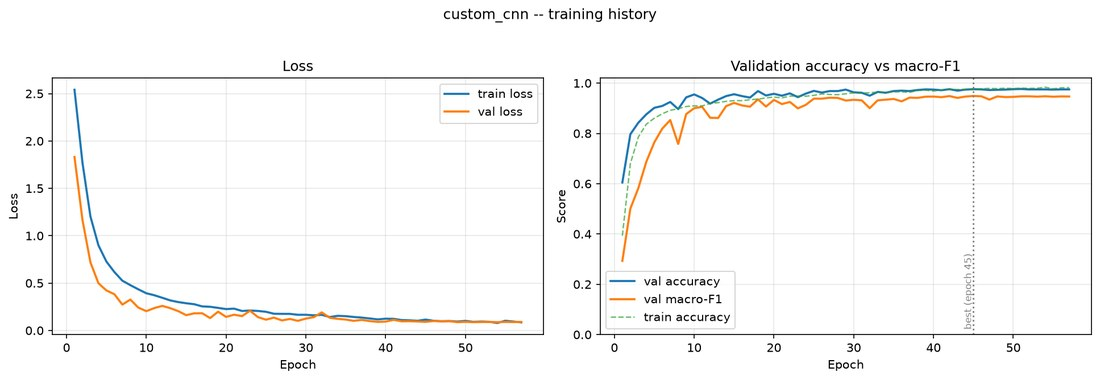

**Per-class precision, recall and F1**

,precision,recall,f1,support
Blip,0.993,0.989,0.991,272
Koi_Fish,0.981,1.000,0.990,102
Low_Frequency_Burst,0.966,0.933,0.949,90
Light_Modulation,0.974,0.974,0.974,78
Power_Line,0.986,1.000,0.993,68
Scattered_Light,0.985,0.970,0.977,67
Low_Frequency_Lines,0.922,0.894,0.908,66
Extremely_Loud,0.955,0.984,0.969,64
Violin_Mode,0.970,1.000,0.985,64
1080Lines,1.000,0.940,0.969,50


**Confusion matrix** (rows = true class, normalised so each row sums to 1)

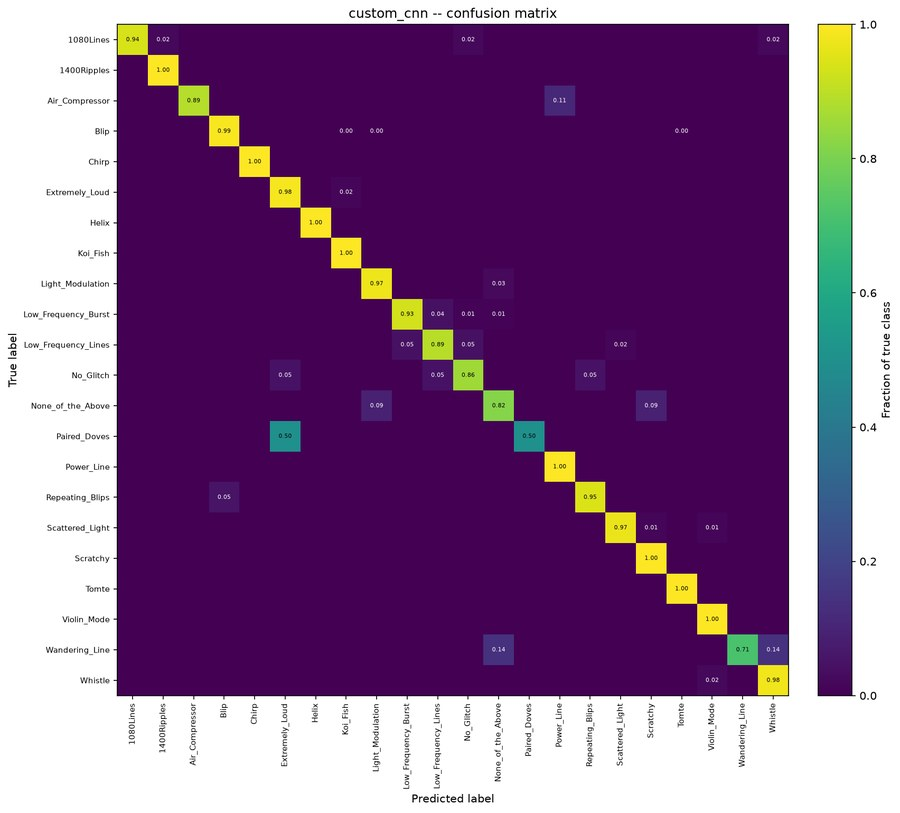

**Correct predictions** (one per class, highest confidence)

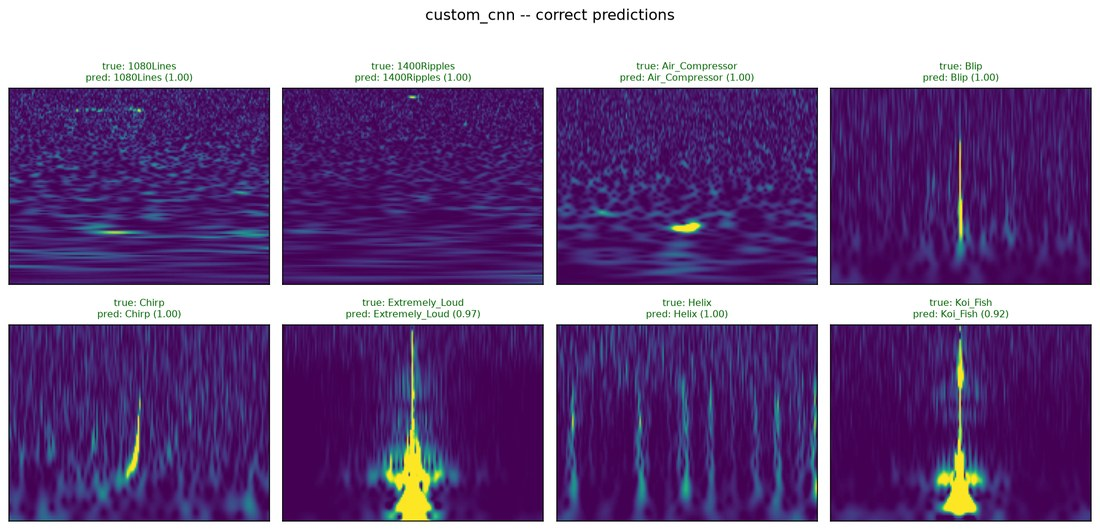

**Most confident mistakes**

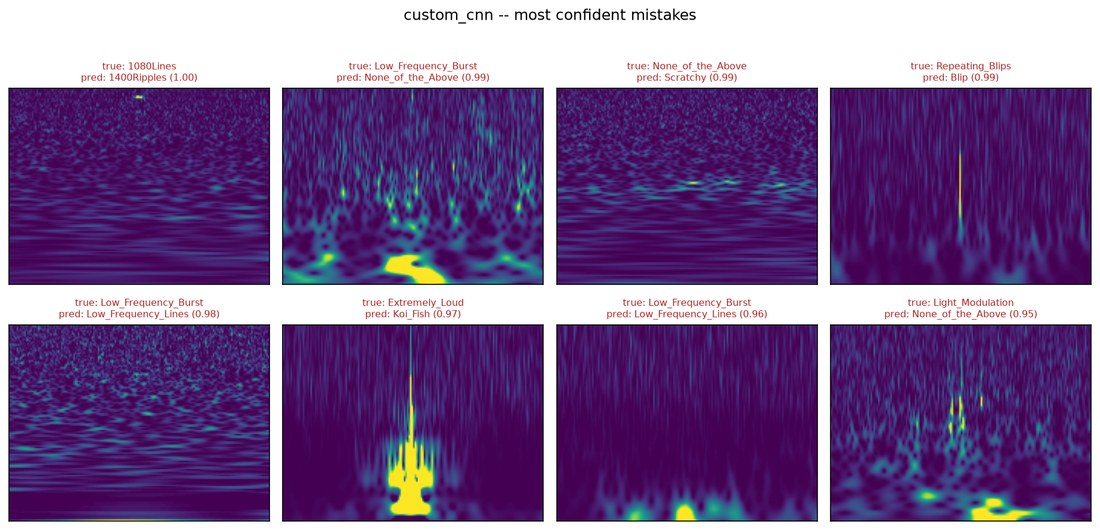

In [19]:
m = "custom_cnn"
display(pd.DataFrame([summary_row(m)], index=[LABELS[m]]))
display(Markdown("**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated."))
show_png(OUT / m / "training_curves.png")
display(Markdown("**Per-class precision, recall and F1**"))
display(per_class(m).round(3))
display(Markdown("**Confusion matrix** (rows = true class, normalised so each row sums to 1)"))
show_png(OUT / m / "confusion_matrix.png", 900)
display(Markdown("**Correct predictions** (one per class, highest confidence)"))
show_png(OUT / m / "examples_correct.png")
display(Markdown("**Most confident mistakes**"))
show_png(OUT / m / "examples_incorrect.png")

### 9.2 EfficientNetV2-S (Student 2)

,macro-F1,accuracy,balanced accuracy,macro precision,macro recall,weighted precision,weighted recall,weighted-F1
EfficientNetV2-S (Student 2),0.9323,0.9686,0.9248,0.9498,0.9248,0.9698,0.9686,0.9686


**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated.

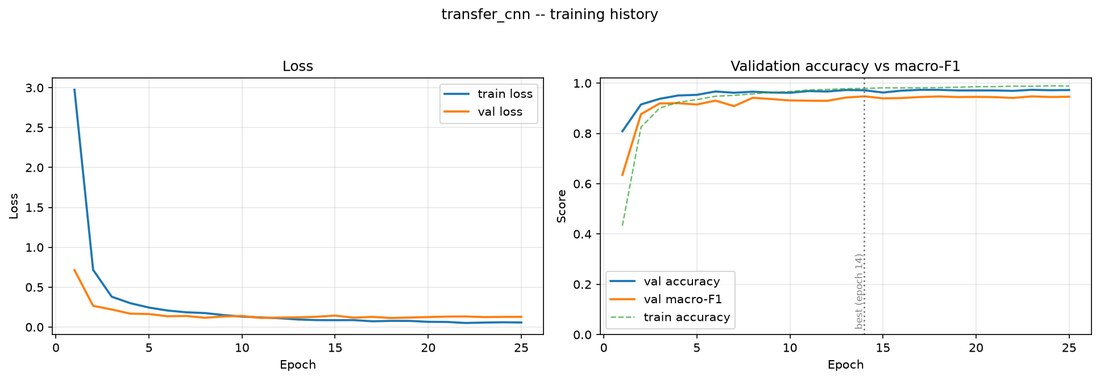

**Per-class precision, recall and F1**

,precision,recall,f1,support
Blip,0.985,0.985,0.985,272
Koi_Fish,0.980,0.980,0.980,102
Low_Frequency_Burst,0.988,0.944,0.966,90
Light_Modulation,0.951,0.987,0.969,78
Power_Line,0.971,1.000,0.986,68
Scattered_Light,0.985,0.955,0.970,67
Low_Frequency_Lines,0.955,0.955,0.955,66
Extremely_Loud,0.926,0.984,0.955,64
Violin_Mode,0.984,0.984,0.984,64
1080Lines,1.000,0.960,0.980,50


**Confusion matrix** (rows = true class, normalised so each row sums to 1)

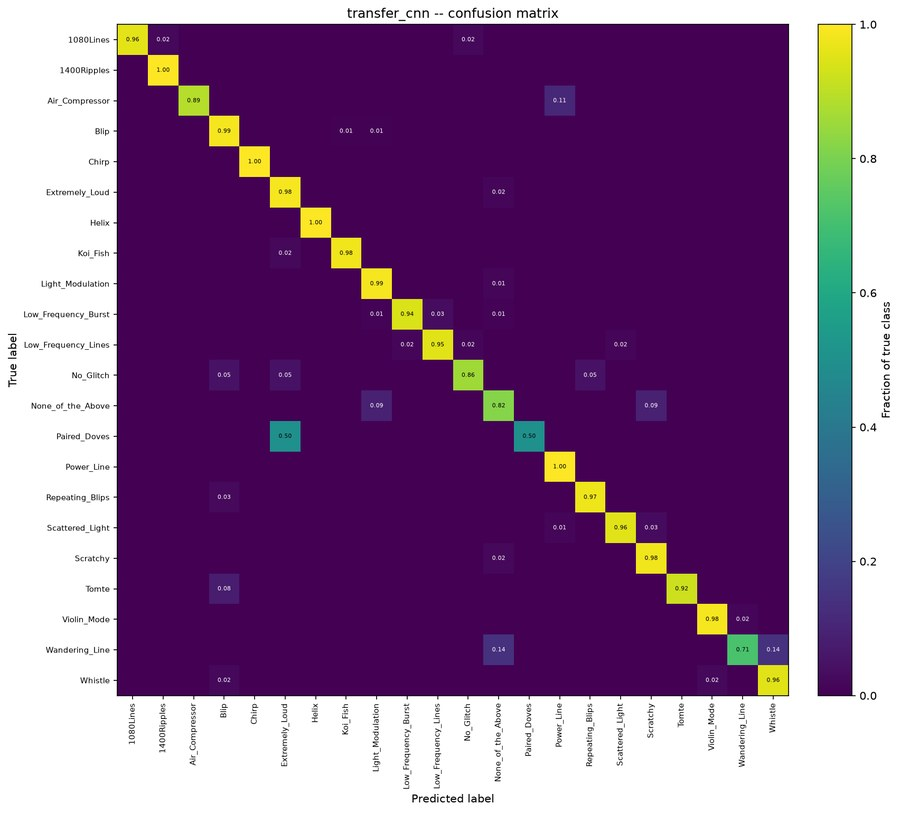

**Correct predictions** (one per class, highest confidence)

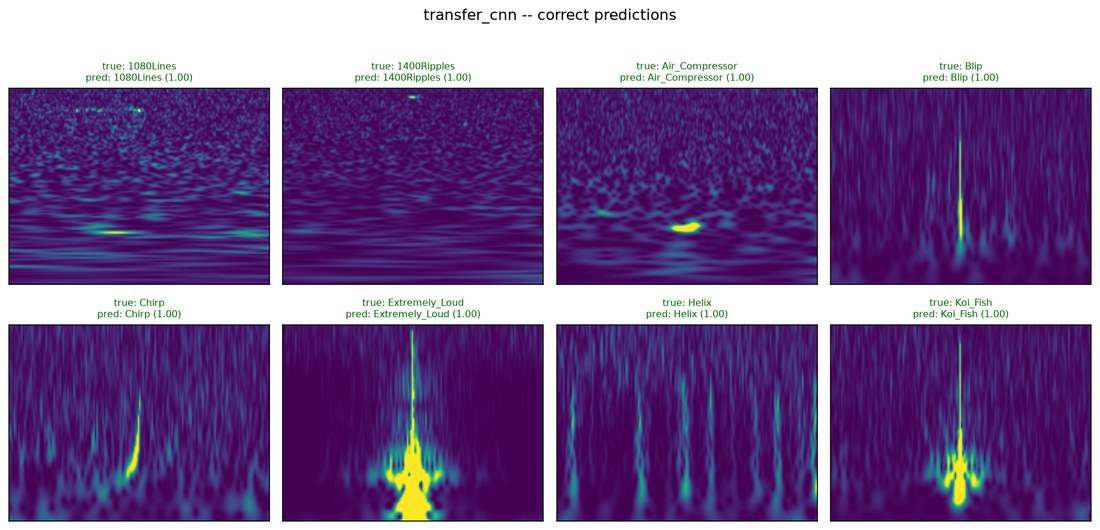

**Most confident mistakes**

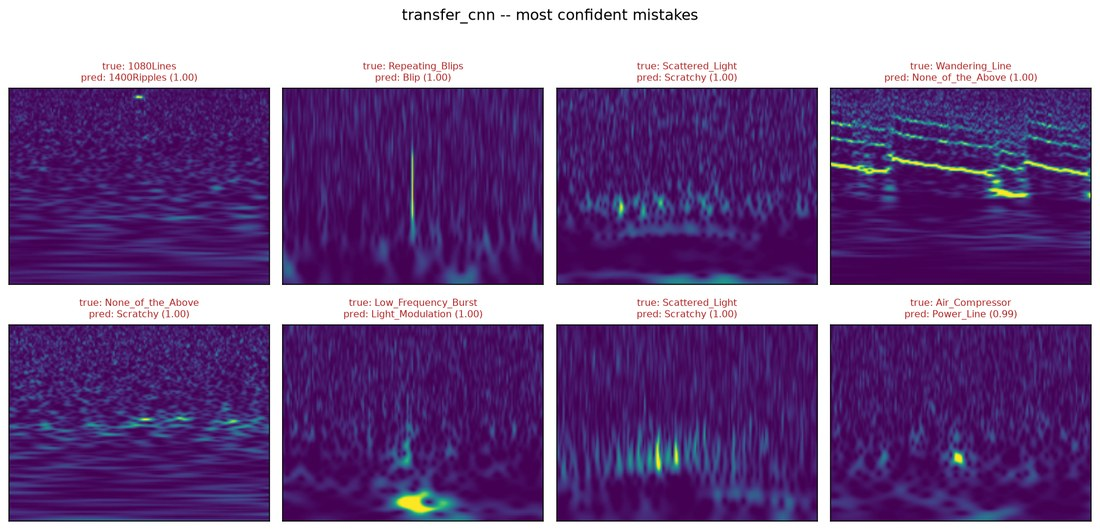

In [20]:
m = "transfer_cnn"
display(pd.DataFrame([summary_row(m)], index=[LABELS[m]]))
display(Markdown("**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated."))
show_png(OUT / m / "training_curves.png")
display(Markdown("**Per-class precision, recall and F1**"))
display(per_class(m).round(3))
display(Markdown("**Confusion matrix** (rows = true class, normalised so each row sums to 1)"))
show_png(OUT / m / "confusion_matrix.png", 900)
display(Markdown("**Correct predictions** (one per class, highest confidence)"))
show_png(OUT / m / "examples_correct.png")
display(Markdown("**Most confident mistakes**"))
show_png(OUT / m / "examples_incorrect.png")

### 9.3 Swin-Tiny (Student 3)

,macro-F1,accuracy,balanced accuracy,macro precision,macro recall,weighted precision,weighted recall,weighted-F1
Swin-Tiny (Student 3),0.9421,0.9712,0.9346,0.9618,0.9346,0.9735,0.9712,0.9712


**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated.

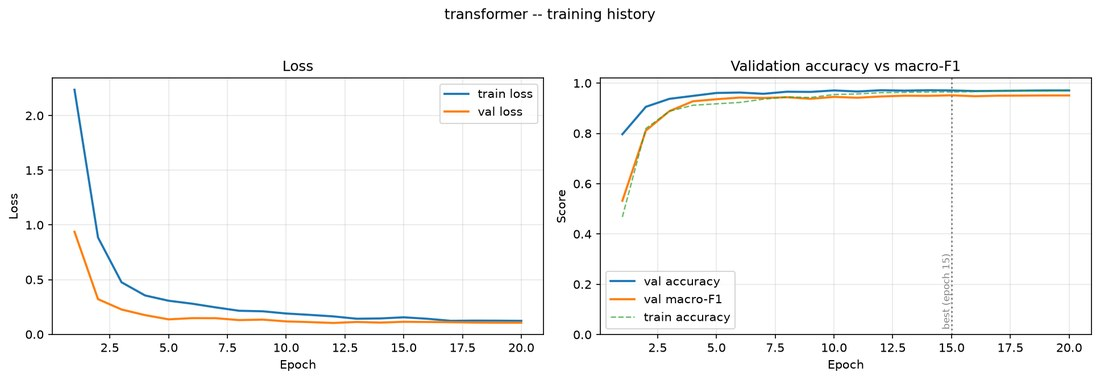

**Per-class precision, recall and F1**

,precision,recall,f1,support
Blip,0.986,1.000,0.993,272
Koi_Fish,0.981,1.000,0.990,102
Low_Frequency_Burst,0.989,0.978,0.983,90
Light_Modulation,0.974,0.974,0.974,78
Power_Line,0.986,1.000,0.993,68
Scattered_Light,0.984,0.940,0.962,67
Low_Frequency_Lines,0.967,0.879,0.921,66
Extremely_Loud,0.954,0.969,0.961,64
Violin_Mode,1.000,0.984,0.992,64
1080Lines,1.000,0.940,0.969,50


**Confusion matrix** (rows = true class, normalised so each row sums to 1)

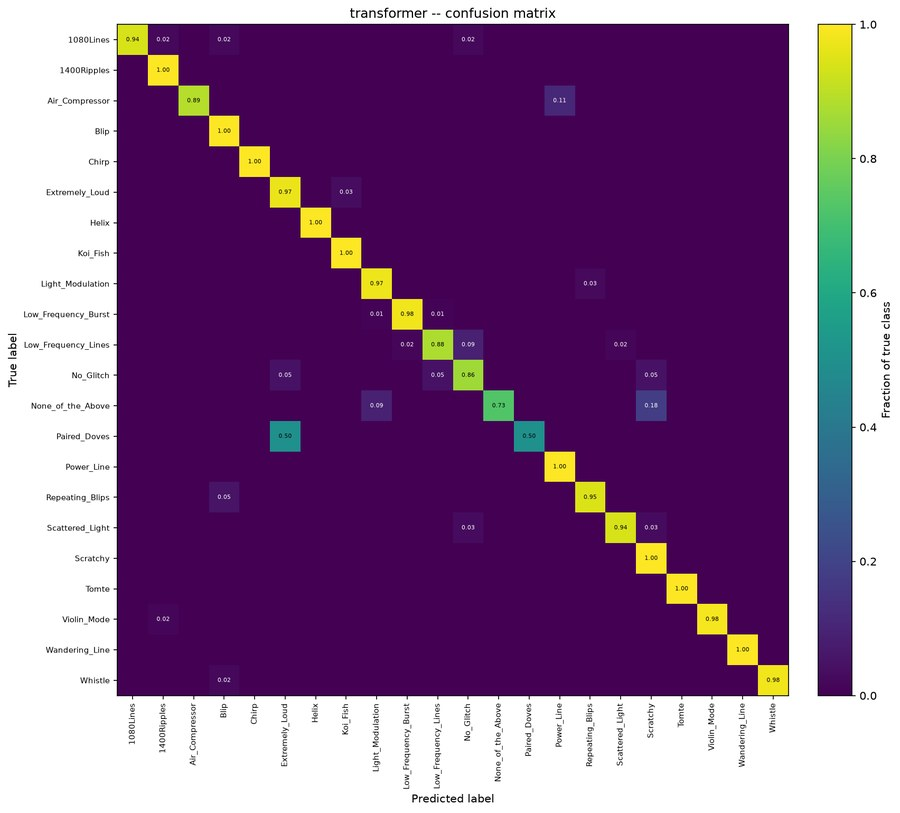

**Correct predictions** (one per class, highest confidence)

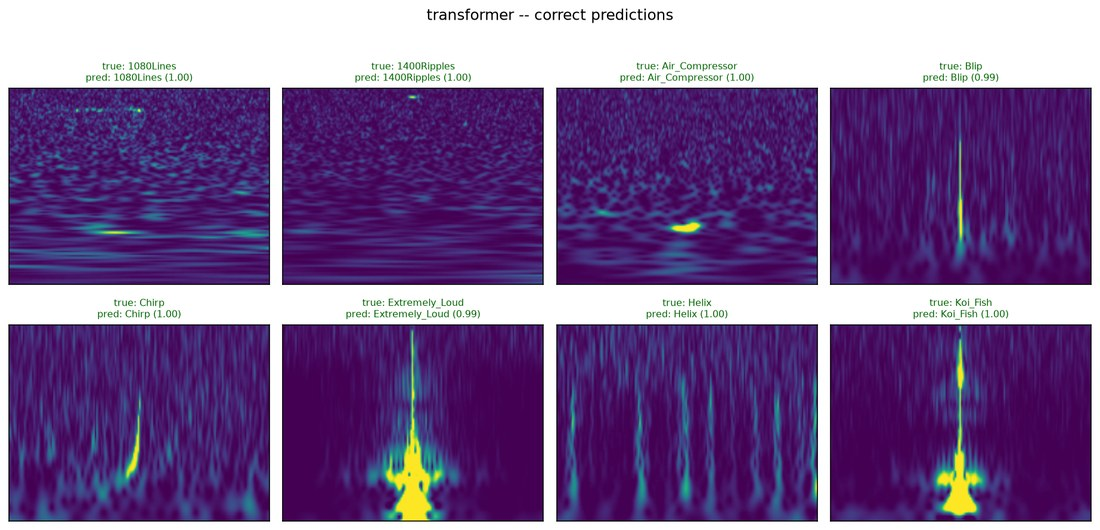

**Most confident mistakes**

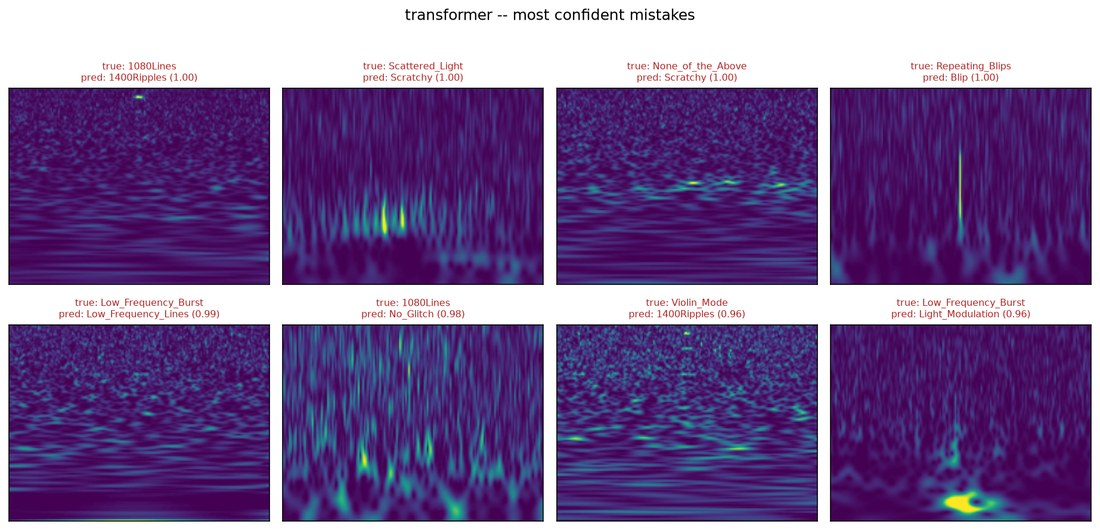

In [21]:
m = "transformer"
display(pd.DataFrame([summary_row(m)], index=[LABELS[m]]))
display(Markdown("**Training and validation curves.** Left: loss. Right: validation accuracy and macro-F1; the dotted line marks the epoch whose checkpoint was evaluated."))
show_png(OUT / m / "training_curves.png")
display(Markdown("**Per-class precision, recall and F1**"))
display(per_class(m).round(3))
display(Markdown("**Confusion matrix** (rows = true class, normalised so each row sums to 1)"))
show_png(OUT / m / "confusion_matrix.png", 900)
display(Markdown("**Correct predictions** (one per class, highest confidence)"))
show_png(OUT / m / "examples_correct.png")
display(Markdown("**Most confident mistakes**"))
show_png(OUT / m / "examples_incorrect.png")

## 10. Model comparison

All three models evaluated on the same 1,179 test glitches.

,macro-F1,accuracy,balanced accuracy,macro precision,macro recall,weighted precision,weighted recall,weighted-F1,parameters (millions),input size,best epoch / epochs run
Swin-Tiny (Student 3),0.9421,0.9712,0.9346,0.9618,0.9346,0.9735,0.9712,0.9712,27.5363,224 x 224,15 / 20
Custom CNN (Student 1),0.9332,0.9686,0.9267,0.9511,0.9267,0.9697,0.9686,0.9684,2.3595,140 x 170,45 / 57
EfficientNetV2-S (Student 2),0.9323,0.9686,0.9248,0.9498,0.9248,0.9698,0.9686,0.9686,20.2057,224 x 224,14 / 25


spread across models:  accuracy 0.0025   macro-F1 0.0097


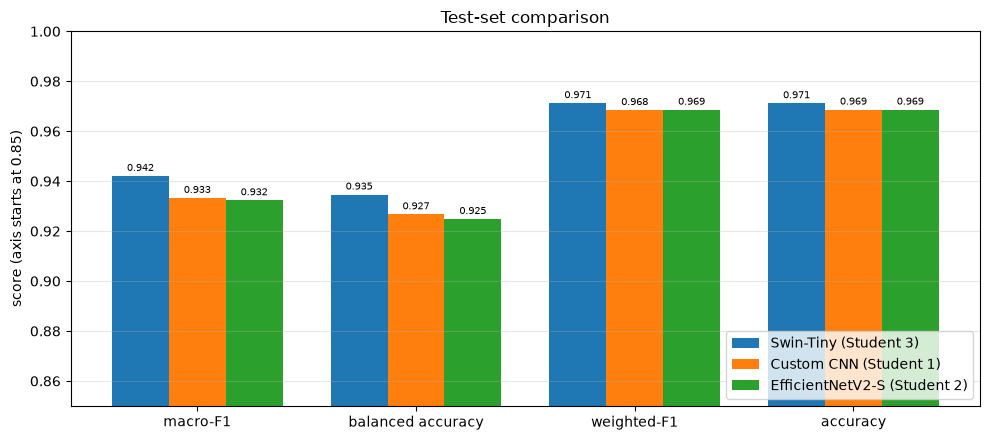

In [22]:
comp = pd.DataFrame({LABELS[m]: {**summary_row(m),
                                 "parameters (millions)": metrics[m]["n_parameters"] / 1e6,
                                 "input size": "%d x %d" % tuple(metrics[m]["input_size"]),
                                 "best epoch / epochs run": "%s / %s" % (metrics[m]["best_epoch"],
                                                                        metrics[m]["epochs_trained"])}
                     for m in MODELS}).T.sort_values("macro-F1", ascending=False)
display(comp)

acc = comp["accuracy"].astype(float); f1 = comp["macro-F1"].astype(float)
print("spread across models:  accuracy %.4f   macro-F1 %.4f"
      % (acc.max() - acc.min(), f1.max() - f1.min()))

keys = ["macro-F1", "balanced accuracy", "weighted-F1", "accuracy"]
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(keys)); w = 0.26
for i, name in enumerate(comp.index):
    vals = [float(comp.loc[name, k]) for k in keys]
    bars = ax.bar(x + (i - 1) * w, vals, w, label=name)
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
ax.set_xticks(x); ax.set_xticklabels(keys)
ax.set_ylim(0.85, 1.0); ax.set_ylabel("score (axis starts at 0.85)")
ax.set_title("Test-set comparison"); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### Per-class F1

Where the models differ. Sorted by number of test images; `spread` is the gap between the best and worst model on that class.

,test images,Custom CNN (Student 1),EfficientNetV2-S (Student 2),Swin-Tiny (Student 3),best,spread
Blip,272,0.991,0.985,0.993,Swin-Tiny,0.007
Koi_Fish,102,0.990,0.980,0.990,Custom,0.010
Low_Frequency_Burst,90,0.949,0.966,0.983,Swin-Tiny,0.034
Light_Modulation,78,0.974,0.969,0.974,Custom,0.006
Power_Line,68,0.993,0.986,0.993,Custom,0.007
Scattered_Light,67,0.977,0.970,0.962,Custom,0.016
Low_Frequency_Lines,66,0.908,0.955,0.921,EfficientNetV2-S,0.047
Extremely_Loud,64,0.969,0.955,0.961,Custom,0.015
Violin_Mode,64,0.985,0.984,0.992,Swin-Tiny,0.008
1080Lines,50,0.969,0.980,0.969,EfficientNetV2-S,0.011


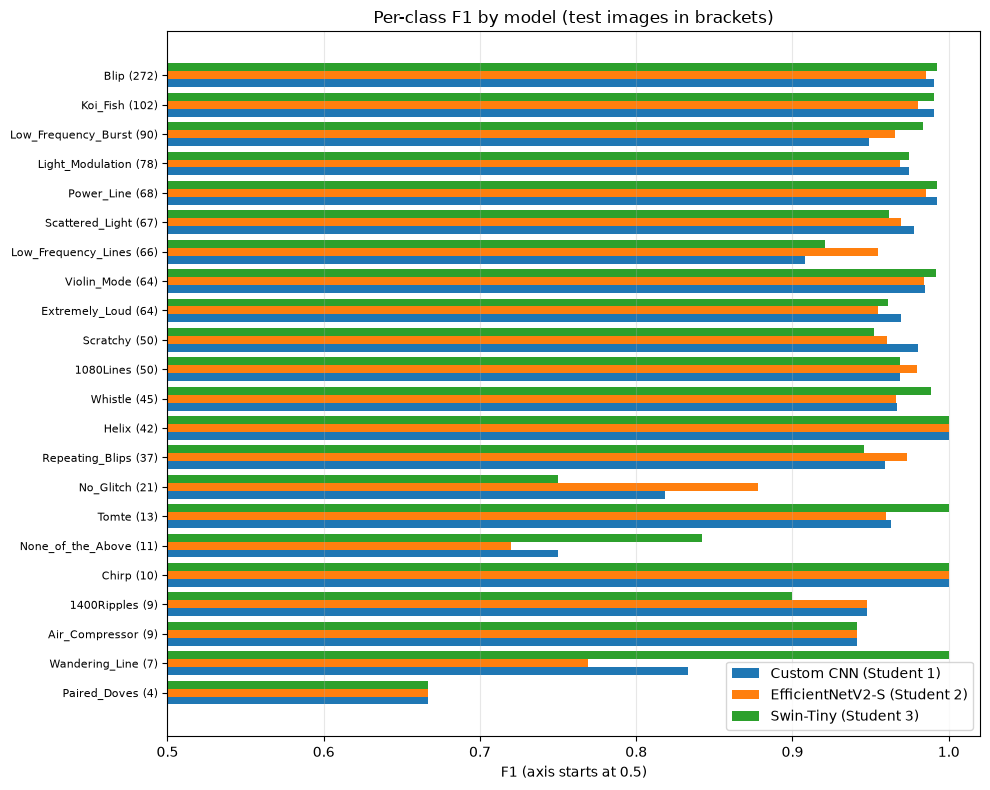

In [23]:
f1c = pd.DataFrame({LABELS[m]: {c: metrics[m]["per_class"][c]["f1"] for c in CLASSES} for m in MODELS})
f1c.insert(0, "test images", [metrics["custom_cnn"]["per_class"][c]["support"] for c in CLASSES])
f1c["best"] = f1c[list(LABELS.values())].idxmax(axis=1).str.split(" ").str[0]
f1c["spread"] = f1c[list(LABELS.values())].max(axis=1) - f1c[list(LABELS.values())].min(axis=1)
display(f1c.sort_values("test images", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 8))
order = f1c.sort_values("test images").index
y = np.arange(len(order)); h = 0.27
for i, name in enumerate(LABELS.values()):
    ax.barh(y + (i - 1) * h, f1c.loc[order, name], h, label=name)
ax.set_yticks(y); ax.set_yticklabels(["%s (%d)" % (c, f1c.loc[c, "test images"]) for c in order], fontsize=8)
ax.set_xlim(0.5, 1.02); ax.set_xlabel("F1 (axis starts at 0.5)")
ax.set_title("Per-class F1 by model (test images in brackets)")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Error analysis

### Most frequent confusions

The largest off-diagonal cells of each confusion matrix (true class → predicted class, number of test images).

In [24]:
def top_confusions(m, k=6):
    cm = np.array(metrics[m]["confusion_matrix"])
    np.fill_diagonal(cm, 0)
    flat = np.argsort(-cm.ravel())[:k]
    return ["%s -> %s (%d)" % (CLASSES[i // len(CLASSES)], CLASSES[i % len(CLASSES)], cm.ravel()[i])
            for i in flat if cm.ravel()[i] > 0]

errors = {LABELS[m]: int(round((1 - metrics[m]["accuracy"]) * metrics[m]["n_samples"])) for m in MODELS}
print("misclassified test images:", errors)
pd.DataFrame({LABELS[m]: pd.Series(top_confusions(m)) for m in MODELS}, ).rename(index=lambda i: i + 1)

misclassified test images: {'Custom CNN (Student 1)': 37, 'EfficientNetV2-S (Student 2)': 37, 'Swin-Tiny (Student 3)': 34}


,Custom CNN (Student 1),EfficientNetV2-S (Student 2),Swin-Tiny (Student 3)
1,Low_Frequency_Burst -> Low_Frequency_Lines (4),Low_Frequency_Burst -> Low_Frequency_Lines (3),Low_Frequency_Lines -> No_Glitch (6)
2,Low_Frequency_Lines -> Low_Frequency_Burst (3),Scattered_Light -> Scratchy (2),Scattered_Light -> Scratchy (2)
3,Low_Frequency_Lines -> No_Glitch (3),Koi_Fish -> Extremely_Loud (2),Repeating_Blips -> Blip (2)
4,Repeating_Blips -> Blip (2),Paired_Doves -> Extremely_Loud (2),Scattered_Light -> No_Glitch (2)
5,Light_Modulation -> None_of_the_Above (2),Blip -> Koi_Fish (2),None_of_the_Above -> Scratchy (2)
6,Paired_Doves -> Extremely_Loud (2),Blip -> Light_Modulation (2),Paired_Doves -> Extremely_Loud (2)


### Do the models make the same mistakes?

If the three architectures fail on the same images, the cause is more likely in the data than in any one model.

In [25]:
preds = {m: pd.read_csv(OUT / m / "predictions.csv").set_index("gravityspy_id") for m in MODELS}
wrong = pd.DataFrame({m: preds[m]["correct"] == 0 for m in MODELS})
n_wrong = wrong.sum(axis=1)
blank_test = set(q.loc[q.blank & (q.split == "test"), "gravityspy_id"])

print("test images: %d" % len(wrong))
for k in range(4):
    sel = n_wrong[n_wrong == k].index
    print("  misclassified by %d of 3 models: %4d   (of which blank: %d)"
          % (k, len(sel), len(set(sel) & blank_test)))
hard = preds["custom_cnn"].loc[n_wrong == 3, "true_label"].value_counts()
print("\ntrue classes of the images that all three models get wrong:")
hard.to_frame("images")

test images: 1179
  misclassified by 0 of 3 models: 1120   (of which blank: 16)
  misclassified by 1 of 3 models:   23   (of which blank: 0)
  misclassified by 2 of 3 models:   23   (of which blank: 0)
  misclassified by 3 of 3 models:   13   (of which blank: 3)

true classes of the images that all three models get wrong:


,images
true_label,
1080Lines,2
No_Glitch,2
None_of_the_Above,2
Paired_Doves,2
Air_Compressor,1
Low_Frequency_Burst,1
Low_Frequency_Lines,1
Repeating_Blips,1
Scattered_Light,1


### Effect of the blank images

Each model scored with and without the 19 blank test images, and what it predicts for them.

In [26]:
rows = []
for m in MODELS:
    p = preds[m]
    is_blank = p.index.isin(blank_test)
    keep = p[~is_blank]
    without = compute_metrics(keep.true_label.map(CLASS_TO_IDX), keep.predicted_label.map(CLASS_TO_IDX), CLASSES)
    pdv = p[p.true_label == "Paired_Doves"]
    pdv_blank = pdv.index.isin(blank_test)
    rows.append({"model": LABELS[m],
                 "macro-F1": metrics[m]["macro_f1"],
                 "macro-F1 without blanks": without["macro_f1"],
                 "difference": without["macro_f1"] - metrics[m]["macro_f1"],
                 "blank images predicted Extremely_Loud": "%d / %d" % ((p[is_blank].predicted_label == "Extremely_Loud").sum(), is_blank.sum()),
                 "Paired_Doves real images correct": "%d / %d" % (pdv[~pdv_blank].correct.sum(), (~pdv_blank).sum()),
                 "Paired_Doves blank images correct": "%d / %d" % (pdv[pdv_blank].correct.sum(), pdv_blank.sum())})
pd.DataFrame(rows).set_index("model").round(4)

,macro-F1,macro-F1 without blanks,difference,blank images predicted Extremely_Loud,Paired_Doves real images correct,Paired_Doves blank images correct
model,,,,,,
Custom CNN (Student 1),0.9332,0.9502,0.0169,19 / 19,2 / 2,0 / 2
EfficientNetV2-S (Student 2),0.9323,0.9491,0.0168,19 / 19,2 / 2,0 / 2
Swin-Tiny (Student 3),0.9421,0.9587,0.0167,19 / 19,2 / 2,0 / 2


**Reading this.** All three architectures assign all 19 blank test images to `Extremely_Loud`, the class most blank training images carry. A blank image contains nothing except which class usually has blanks, so this is the best possible guess, not a model fault. It means:

- `Paired_Doves` scores exactly 0.667 for **every** model: the 2 real test images are always classified correctly and the 2 blank ones never can be.
- The defect costs each model about the same macro-F1 (~0.017), so it **does not change the ranking**.

## 12. Summary

In [27]:
best = comp.index[0]
runner = comp.index[1]
gap = float(comp.loc[best, "macro-F1"]) - float(comp.loc[runner, "macro-F1"])
print("highest test macro-F1 : %s, %.4f" % (best, float(comp.loc[best, "macro-F1"])))
print("margin over 2nd       : %.4f (%s)" % (gap, runner))
print("accuracy, all models  : %.4f to %.4f" % (acc.min(), acc.max()))
cnn = float(comp.loc[LABELS["custom_cnn"], "macro-F1"]); eff = float(comp.loc[LABELS["transfer_cnn"], "macro-F1"])
print("custom CNN vs EfficientNetV2-S: %.4f vs %.4f with %.0fx fewer parameters"
      % (cnn, eff, metrics["transfer_cnn"]["n_parameters"] / metrics["custom_cnn"]["n_parameters"]))

highest test macro-F1 : Swin-Tiny (Student 3), 0.9421
margin over 2nd       : 0.0088 (Custom CNN (Student 1))
accuracy, all models  : 0.9686 to 0.9712
custom CNN vs EfficientNetV2-S: 0.9332 vs 0.9323 with 9x fewer parameters


**Limitations to keep in mind when interpreting the comparison:**

- **One training run per model.** The differences between models are small, and a single seed cannot show whether they would hold with different random initialisation. The custom CNN reproduced exactly across three runs with the same seed; the pretrained models were trained once.
- **Rare classes have very few test images.** Paired_Doves has 4 and Wandering_Line 7, so a single image moves their F1 a lot.
- **Blank images** affect 1.7% of the data and set a ceiling on Paired_Doves (section 11).
- **Light tuning.** Hyperparameters follow standard practice for each architecture rather than an extensive search, and the effort was similar for each model.
- **One duration view (2.0 s).** Classes that differ mainly in how long they last, such as Low_Frequency_Burst and Low_Frequency_Lines, may be easier to separate with the 4.0 s view or by combining views.

### References

- Bahaadini, S. et al. (2018). Machine learning for Gravity Spy: Glitch classification and dataset. *Information Sciences*, 444, 172–186.
- Zevin, M. et al. (2017). Gravity Spy: Integrating Advanced LIGO detector characterization, machine learning, and citizen science. *Classical and Quantum Gravity*, 34(6), 064003.
- Gravity Spy training set v1.1, Zenodo, doi:10.5281/zenodo.1476551 (CC BY 4.0).
- Park, D. S. et al. (2019). SpecAugment: A simple data augmentation method for automatic speech recognition. arXiv:1904.08779.
- Tan, M. & Le, Q. (2021). EfficientNetV2: Smaller models and faster training. *ICML*.
- Liu, Z. et al. (2021). Swin Transformer: Hierarchical vision transformer using shifted windows. *ICCV*.
- Wightman, R. PyTorch Image Models (timm). https://github.com/huggingface/pytorch-image-models